In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from neo4j import GraphDatabase
from sklearn.decomposition import PCA

transactions = pd.read_csv("../data/transactions.csv")
user_accounts = pd.read_csv("../data/user_accounts.csv")
user_devices = pd.read_csv("../data/user_devices.csv")
user_ips = pd.read_csv("../data/user_ips.csv")
embeddings = pd.read_csv("../data/node_embeddings.csv")

print(f"Transactions: {len(transactions):,} | Fraud Flagged: {transactions['is_synthetic_fraud'].sum():,}")
print(f"Users/Accounts rows: {len(user_accounts):,} | Node Embeddings: {embeddings.shape}")
transactions.head()

Transactions: 2,020 | Fraud Flagged: 20
Users/Accounts rows: 500 | Node Embeddings: (329, 17)


,tx_id,sender_account,receiver_account,amount,is_synthetic_fraud
0,TX_000001,ACC_0144,ACC_0561,127.32,False
1,TX_000002,ACC_0501,ACC_0189,762.53,False
2,TX_000003,ACC_0556,ACC_0061,339.19,False
3,TX_000004,ACC_0537,ACC_0035,238.24,False
4,TX_000005,ACC_0077,ACC_0050,52.41,False


In [2]:
URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "password123"

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

with driver.session() as session:
    session.run("CALL gds.graph.drop('fraudGraph', false)")
    session.run("""
        MATCH (a:Account)
        OPTIONAL MATCH (a)-[:SENT]->(:Transaction)-[:RECEIVED_BY]->(target:Account)
        WITH gds.graph.project('fraudGraph', a, target) AS g
        RETURN g.graphName
    """)
    louvain_rows = session.run("""
        CALL gds.louvain.stream('fraudGraph')
        YIELD nodeId, communityId
        RETURN gds.util.asNode(nodeId).id AS account_id, communityId
    """).data()
    session.run("CALL gds.graph.drop('fraudGraph', false)")

driver.close()

louvain_df = pd.DataFrame(louvain_rows)
community_sizes = louvain_df["communityId"].value_counts().reset_index()
community_sizes.columns = ["communityId", "member_count"]

print(f"Total Louvain Communities Detected: {len(community_sizes)}")
print("\nTop 10 Largest Account Communities:")
print(community_sizes.head(10))

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. `schema` returned by the procedure `gds.graph.drop` is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('fraudGraph', false)"
Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. `schema` returned by the procedure `gds.graph.drop` is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClass

Total Louvain Communities Detected: 28

Top 10 Largest Account Communities:
   communityId  member_count
0          259            76
1          172            46
2            3            32
3          104            30
4           71            23
5          306            22
6          228            16
7           28            16
8          292            15
9          145            15


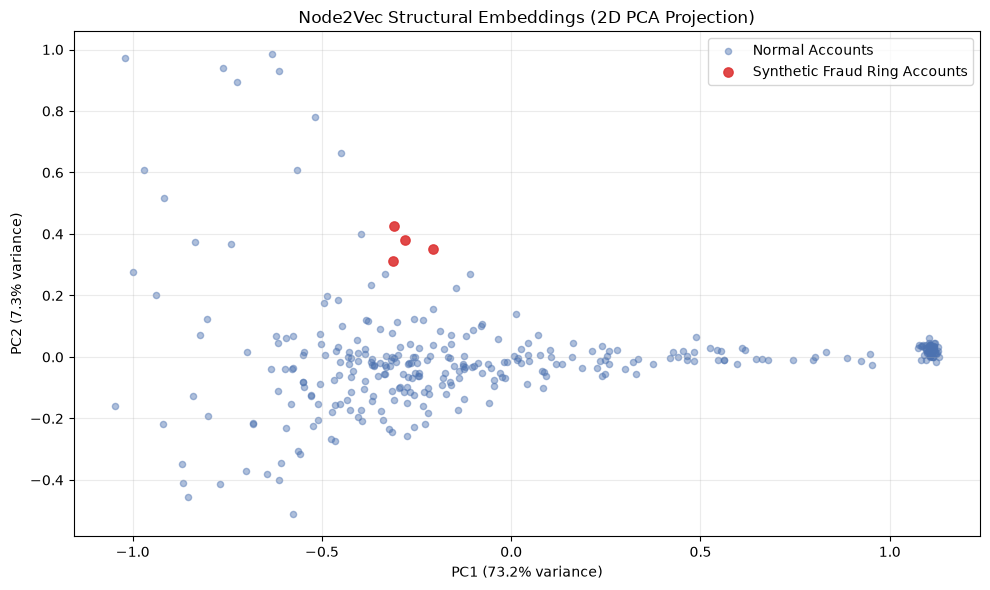

In [3]:
fraud_tx = transactions[transactions["is_synthetic_fraud"].astype(bool)]
fraud_accounts = set(fraud_tx["sender_account"]).union(set(fraud_tx["receiver_account"]))

embeddings["is_fraud_ring"] = embeddings["account_id"].isin(fraud_accounts)

feature_cols = [col for col in embeddings.columns if col.startswith("emb_")]
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(embeddings[feature_cols])

embeddings["pca_1"] = coords[:, 0]
embeddings["pca_2"] = coords[:, 1]

plt.figure(figsize=(10, 6))
normal = embeddings[~embeddings["is_fraud_ring"]]
fraud = embeddings[embeddings["is_fraud_ring"]]

plt.scatter(normal["pca_1"], normal["pca_2"], alpha=0.45, s=20, label="Normal Accounts", color="#4C72B0")
plt.scatter(fraud["pca_1"], fraud["pca_2"], alpha=0.9, s=45, label="Synthetic Fraud Ring Accounts", color="#DD3434")

plt.title("Node2Vec Structural Embeddings (2D PCA Projection)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [4]:
device_col = user_devices.columns[1]
ip_col = user_ips.columns[1]

shared_devices = (
    user_devices.groupby(device_col)["user_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(5)
)

shared_ips = (
    user_ips.groupby(ip_col)["user_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 Shared Devices (Distinct Users):")
print(shared_devices)
print("\nTop 5 Shared IPs (Distinct Users):")
print(shared_ips)

Top 5 Shared Devices (Distinct Users):
device_id
DEV_0001    44
DEV_0062     7
DEV_0098     6
DEV_0191     6
DEV_0035     5
Name: user_id, dtype: int64

Top 5 Shared IPs (Distinct Users):
ip_address
IP_0001    62
IP_0121     9
IP_0126     8
IP_0087     7
IP_0058     7
Name: user_id, dtype: int64
